<a href="https://colab.research.google.com/github/Mohammad1s/Stroke-Prediction/blob/main/FPrjct.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **importing Dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('healthcare-dataset-stroke-data.csv')

print("File loaded successfully!")
df.head() #عرض اول 5 صفوف

File loaded successfully!


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


# **Data Preprocessing**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Handle Missing Values
# The 'bmi' column has missing values (NaN). We fill them with the mean BMI.
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())

# Drop the 'id' column as it is not useful for prediction
df = df.drop('id', axis=1)

# Encode Categorical Features ---
# We use LabelEncoder for binary/simple text and One-Hot Encoding (get_dummies) for complex ones.
# 1. Label Encode Gender (Male/Female -> 0/1)
le = LabelEncoder()
df['gender'] = le.fit_transform(df['gender'])

# One-Hot Encode the rest ('work_type', 'smoking_status', etc.)
# drop_first=True avoids the "dummy variable trap"
df = pd.get_dummies(df, columns=['ever_married', 'work_type', 'Residence_type', 'smoking_status'], drop_first=True)

# Split Data
X = df.drop('stroke', axis=1)
y = df['stroke']

# Split into Training and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling
# Scale numerical features to improve model performance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Features shape:", X_train_scaled.shape)

Training Features shape: (4088, 15)


# **training**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Initialize models with class_weight='balanced'
log_reg = LogisticRegression(random_state=42, class_weight='balanced')
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Train models
log_reg.fit(X_train_scaled, y_train)
rf_clf.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

# **Evaluation**

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Logistic Regression Evaluation
# Get Predictions
y_pred_log = log_reg.predict(X_test_scaled)

# Print Scores
print("--- Logistic Regression Results ---")
print("Accuracy: ", accuracy_score(y_test, y_pred_log))
# zero_division=0 fixes errors if the model predicts '0' strokes
print("Precision:", precision_score(y_test, y_pred_log, zero_division=0))
print("Recall:   ", recall_score(y_test, y_pred_log))

print("\n") # Just adds an empty line for spacing

# Random Forest Evaluation
# Get Predictions
y_pred_rf = rf_clf.predict(X_test_scaled)

# Print Scores
print("--- Random Forest Results ---")
print("Accuracy: ", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:   ", recall_score(y_test, y_pred_rf))

--- Logistic Regression Results ---
Accuracy:  0.7504892367906066
Precision: 0.16838487972508592
Recall:    0.7903225806451613


--- Random Forest Results ---
Accuracy:  0.9393346379647749
Precision: 0.0
Recall:    0.0


# **Confusion Matrix**

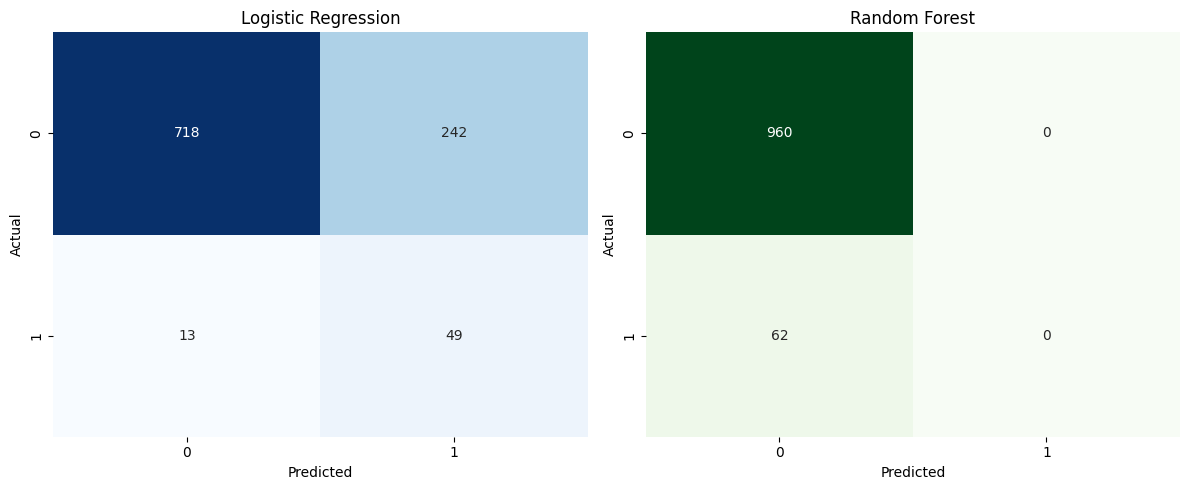

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure that holds 2 plots side-by-side
plt.figure(figsize=(12, 5))

# Logistic Regression
plt.subplot(1, 2, 1) # (1 row, 2 columns, this is plot #1)
cm_log = confusion_matrix(y_test, y_pred_log)
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')

# Random Forest
plt.subplot(1, 2, 2) # (1 row, 2 columns, this is plot #2)
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title('Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

## **ROC curve**

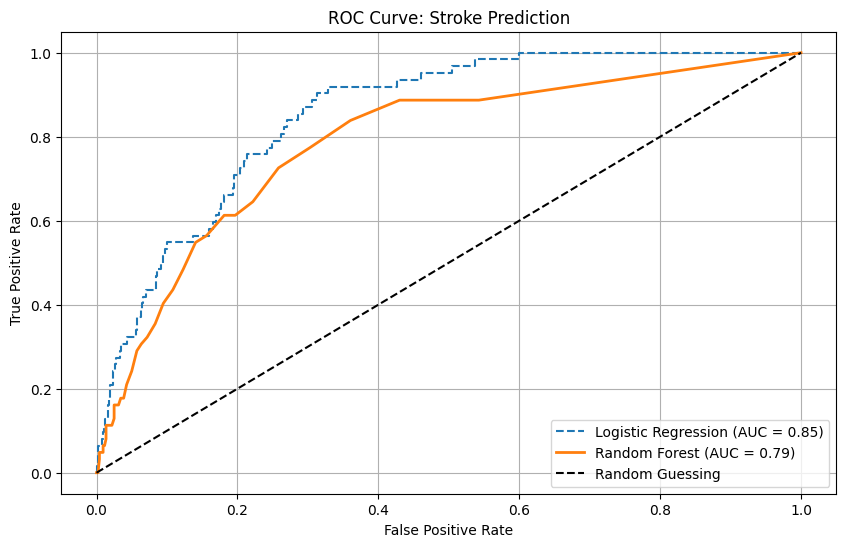

In [ ]:
from sklearn.metrics import roc_curve, auc

# Get probability scores
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = rf_clf.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC points
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# Calculate AUC
auc_log = auc(fpr_log, tpr_log)
auc_rf = auc(fpr_rf, tpr_rf)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(fpr_log, tpr_log, label=f'Logistic Regression (AUC = {auc_log:.2f})', linestyle='--')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Stroke Prediction')
plt.legend()
plt.grid(True)
plt.show()